## DATA ANALYSIS FOR THE ML PROJECT

# Importing and display of the data


In [55]:
import numpy as np
import implementations
from helpers import *
from aux_exploratory_data_analysis import *
from aux_cleaning_functions import *
import csv

In [31]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")

In [ ]:
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [40]:
import os

file_path = os.path.join("data", "x_train.csv")

# 1. Read headers from the CSV inside the 'data' folder
with open(file_path, "r") as f:
    headers = f.readline().strip().split(",")

# Get shape dimensions from the 2D NumPy array
num_rows, num_columns = x_train.shape

print(f"Headers: {headers}")
print(f"Number of columns: {num_columns}")
print(f"Number of rows: {num_rows}")

Headers: ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'FVORANG', 'VEGETAB1', 'EXERAN

In [33]:
for row in (x_train[:5]): #Display the first rows of the dataset to get a better understanding of the data.
    print (row)

[5.30000000e+01 1.10000000e+01 1.11620150e+07 1.10000000e+01
 1.60000000e+01 2.01500000e+03 1.10000000e+03 2.01501563e+09
 2.01501563e+09            nan            nan            nan
            nan            nan            nan            nan
            nan            nan 1.00000000e+00 1.00000000e+00
 2.00000000e+00 1.00000000e+00            nan 1.00000000e+00
 1.00000000e+00 2.00000000e+00 2.00000000e+00 1.00000000e+00
 5.00000000e+00 8.80000000e+01 1.00000000e+00 1.00000000e+00
 2.00000000e+00 1.00000000e+00 3.00000000e+00            nan
 1.00000000e+00 1.00000000e+00 2.00000000e+00 2.00000000e+00
 2.00000000e+00            nan 2.00000000e+00 2.00000000e+00
 2.00000000e+00 2.00000000e+00 1.00000000e+00 2.00000000e+00
 3.00000000e+00            nan 2.00000000e+00 1.00000000e+00
 5.00000000e+00 1.00000000e+00            nan            nan
            nan 2.00000000e+00 1.00000000e+00 8.80000000e+01
 8.00000000e+00 1.00000000e+00 1.10000000e+02 5.01000000e+02
            nan 1.000000

# Cleaning of the dataset

Exploring Nans;

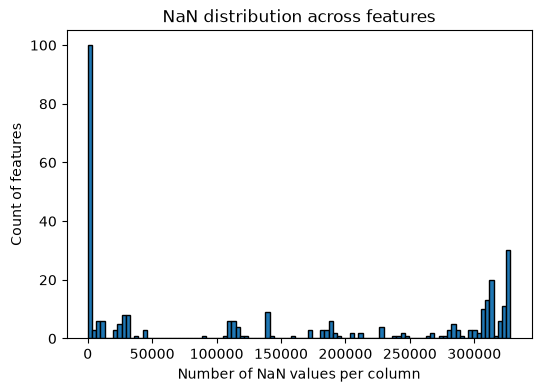

In [34]:
nan_number, nan_pctg = nan_count(x_train ,plot = True)

We can see in our plot that there are aproximately 100 features with 0 Nans and more than 30 that have over 300.000 Nans 

In [39]:
print(f'Percentage of NaN values per column {np.round(nan_pctg)}')

Percentage of NaN values per column [  0.   0.   0.   0.   0.   0.   0.   0.   0.  42.  42. 100.  42.  42.
 100.  42.  43.  43.  58.  58.  58.  58. 100.  58.  58.  59.   0.   0.
   0.  49.   0.   0.   0.   0.   0.  60.   0.  13.  13.   0.   0.  87.
   0.   0.   0.   0.   0.   0.   0.  87.   0.   0.   0.   0.  42.  97.
  42.   0.   0.   0.   1.   1.   1.   1.  85.   2.   2.   3.   3.   3.
   3.   3.   3.  58.  86.  72.   3.   4.  52.  52.  52.   6.   7.   7.
   7.   7.   7.   8.  33.  33.  33.  33.  55.  55.   9.  69.  69.  69.
  70.   9.   9.  57.  57.   9.  10.  74.  74.  81.  81.  93.  93.  93.
  93.  93.  93.  93.  93.  93.  75.  95.  95.  95.  95.  95.  95.  95.
  81.  99.  99.  99. 100.  99.  99.  99.  99.  99.  74.  97.  97.  99.
  97.  97.  91.  94.  91. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100.  96.  97.  99.  99.  99.  96.  96.  96.  96.  91.  98.
 100.  94.  95.  96.  95.  95.  95.  98.  95.  99.  99.  88.  96.  88.
  91.  91.  99.  99.  99.  99.  99.  99. 

Cleanin Nans; 

In [56]:
keep_mask_nan = remove_nan_feat(x_train, threshold=0.3)
# keep mask of features with less than `threshold` proportion of NaN values

In [57]:
X_clean_nan = x_train[:, keep_mask_nan]

In [58]:
cat_mask, num_mask = detect_categorical_features(X_clean_nan, max_unique=30)
#cat_mask : np.ndarray of bool Boolean mask of categorical columns.
#num_mask : np.ndarray of bool  Boolean mask of numerical columns.

Some funcitons to know more about specific columns; 

In [46]:
stats = summarize_basic(x_train , cat_mask)
#Dictionary containing mean, std, min, max, median, and mode (if categorical)

Feature 10
  Mean:   1.0002
  Std:    0.0130
  Min:    1.0000
  Max:    2.0000
  Median: 1.0000
  Mode:   1.0


In [50]:
j = 150 # Which column are we analyzing
show_feature_stats(stats, j) 

Feature 150
  Mean:   680.4846
  Std:    364.3493
  Min:    1.0000
  Max:    999.0000
  Median: 888.0000
  Mode:   888.0


In [59]:
plot_feature_distribution(x_train, cat_mask, j, bins=30)
# plot of the feature we choose 


IndexError: index 150 is out of bounds for axis 0 with size 144

Exploring Outliers; 

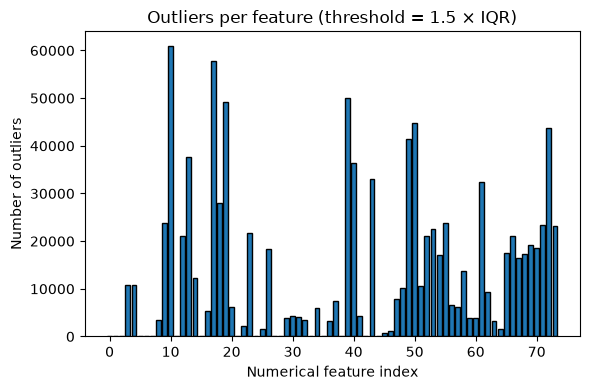

In [52]:
outlier_mask, outlier_counts = detect_outliers(x_train, num_mask, threshold=1.5, plot=True)
#Detects outliers in numerical features using the IQR method.

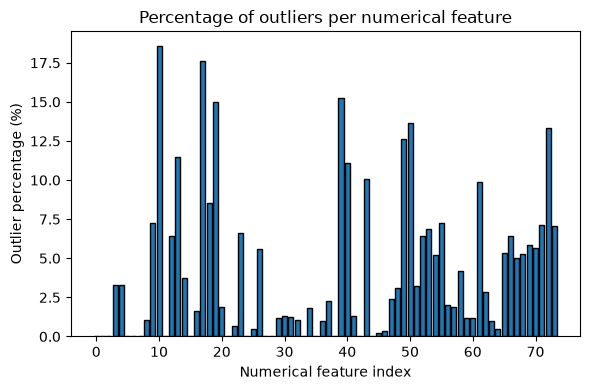

In [53]:
outlier_pctg = summarize_outliers(outlier_mask, num_mask, plot=True)

Cleaning outliers;

In [60]:
keep_mask_out = remove_outliers_feat(X_clean_nan, num_mask, threshold_IQR=1.5, threshold_out=0.3)
X_clean_out = X_clean_nan[:, keep_mask_out]

In [61]:
cat_mask, num_mask = detect_categorical_features(X_clean_nan, max_unique=30)


In [62]:
print(f'Number of categorical columns; {np.sum(cat_mask)} \nNumber of numerical columns {np.sum(num_mask)}')

Number of categorical columns; 105 
Number of numerical columns 39


@Sempere m'he quedat aqui, penso que hara haruiem de fer el que vas fer tu de substiuir els Nans que queden per median o algo aixi i despres standaritzar, pero no tinc 100% clar com fer-ho, suposo que millor amb les funcions que ja estan fetes, t'he fet una llista abaix millor pq poter es mes facil llavors  ( no se si s'ha de fer numeric i categoric junt o per separat milllor )

In [ ]:

X_imputed = impute_missing_values(X_imputed, strategy="normal")
## Replace NaN values with column-wise mean, median or normal sampling.
## strategy: "mean", "median" or "normal"

X_imp, values = impute_numerical(X_imp, num_mask, medians=None, means=None, strategy='medians'):
#Imputes NaN values in numerical features with their medians, means, or samples from a normal distribution.
#If predefined medians or means are provided, they are used instead.

X_imp, modes = impute_categorical(X, cat_mask, modes=None)
#Imputes NaN values in categorical features with the mode (most frequent value).
#If predefined modes are provided, they are used instead.

X_std, means, stds= standardize_features(X, num_mask=None, means=None, stds=None):
#Standardizes numerical features (mean 0, std 1).
#Non-numerical (categorical / one-hot) features are left unchanged.

Una vegada acabat aixo hem de gestionar quan 0s i 1s hi ha en la y i per aixo s'utilitza alugnes funcions, depen del que voluhguyem fer es un proces o un altre, una fucnion qeu podem utilitzar es aquesta; 

In [ ]:
X_bal, y_bal =  balance_data(X, y, method="undersample", random_state=None):
#Balances a binary dataset using only NumPy.


In [ ]:
nan_percentages = {} #Clean the dataset by checking for columns with a high percentage of NaN values and removing them from the dataset.

for col in headers:
    nan_cou = np.isnan(x_train[col]).sum()
    nan_percentage = (nan_cou / num_rows)
    nan_percentages[col] = nan_percentage


high_nan_columns = [col for col, pct in nan_percentages.items() if pct > 0.5] #List of the high percentage NaN columns.
print (f"The number of columns with more than half percent of Nan values is {len(high_nan_columns)}")
                    
cols_to_keep = [col for col in headers if col not in high_nan_columns]  
x_train_clean = np.column_stack([x_train[col] for col in cols_to_keep])

print (f"The shape of the cleaned dataset is {x_train_clean.shape}")

The number of columns with more than half percent of Nan values is 147
The shape of the cleaned dataset is (328135, 175)


In [ ]:
#Now we will check for the remaining NaN values in the dataset and replace them with the mean of each column.

for i in range (len(cols_to_keep)):
    col_data = x_train_clean[:, i]
    nan_left = np.isnan(col_data)
    if nan_left.any():
       col_mean_value = np.nanmean(col_data)
       col_data[nan_left] = col_mean_value


total_nan_left = np.isnan(x_train_clean).sum()
print (f"The total NaN values lefet in the dataset is {total_nan_left}")

#Normalization;
mean = np.mean (x_train_clean, axis = 0)
std = np.std (x_train_clean, axis = 0)

std[std == 0] = 1

x_train_normalized = (x_train_clean - mean) / std

num_cols_clean = x_train_normalized.shape[1]
num_rows_clean = x_train_normalized.shape[0]


print (num_cols_clean, num_rows_clean)

175 328135


One hot encode -> transform cataegroical data into binary 0 and 1s; 

In [ ]:
# Fit one-hot encoder on training data
x_tr_enc, categories = one_hot_encode(x_tr_filt, cat_mask, drop_first=True)

# Apply the same categories to validation and test data
x_va_enc, _ = one_hot_encode(x_va_filt, cat_mask, categories, drop_first=True)
x_te_enc, _ = one_hot_encode(x_te_filt, cat_mask, categories, drop_first=True)
x_test_enc, _ = one_hot_encode(x_test_filt, cat_mask, categories, drop_first=True)

# Studying the colinearity of the data


There are also some funcitons to study correaltaion: 


In [ ]:
mask = feature_target_correlation(X, y, threshold_elimination=0.01):
#Computes Pearson correlation between each feature and the target y
# and returns a boolean mask indicating features with |correlation| above threshold.
corr_matrix = correlation_matrix(X):
#Computes the Pearson correlation matrix between all features.

In [ ]:
corr_matrix = np.corrcoef(x_train_normalized, rowvar=False)

high_correlated_pairs = []

for i in range (num_cols_clean):
    for j in range (i + 1, num_cols_clean):
        if abs(corr_matrix[i, j]) > 0.9:
            high_correlated_pairs.append((cols_to_keep[i], cols_to_keep[j], corr_matrix[i, j]))

print (f"The variable pairs with a high correlation are: ", end = "\n")
for pair in high_correlated_pairs:
    print (f"{pair[0]} and {pair[1]}: {pair[2]:.3f}")